In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import pandas as pd
file_path = '/content/drive/MyDrive/HateSpeechDataset.csv'

# Auto-detect separator
df = pd.read_csv(file_path, sep=None, engine='python', on_bad_lines='skip')

# Force a specific separator and quoting
df = pd.read_csv(file_path, sep=',', quotechar='"',
                 on_bad_lines='skip', engine='python')

# Keep only the first 3 columns and ignore extra ones
df = pd.read_csv(file_path, usecols=range(3), on_bad_lines='skip')

In [ ]:
print(df.shape)
print(df.dtypes)
print(df['Label'].value_counts())
print(df.head(2))

(440906, 3)
Content        object
Label          object
Content_int    object
dtype: object
Label
0        361594
1         79305
Label         7
Name: count, dtype: int64
                                             Content Label  \
0  denial of normal the con be asked to comment o...     1   
1  just by being able to tweet this insufferable ...     1   

                                         Content_int  
0  [146715, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11,...  
1  [146715, 14, 15, 16, 17, 7, 18, 19, 20, 21, 22...  


In [ ]:
# Remove corrupted rows where Label == 'Label' (7 rows, re-inserted headers)
df = df[df['Label'] != 'Label']                    # we define: filter — keeps only valid 0/1 rows

# Convert Label to proper integer type
df['Label'] = df['Label'].astype(int)               # inbuilt: astype — was object due to mixed 'Label' strings

# Drop Content_int — it's a leftover tokenized column, not needed for TF-IDF pipeline
df = df.drop(columns=['Content_int'])                # inbuilt: drop

# Reset index after filtering
df = df.reset_index(drop=True)                       # inbuilt: reset_index

print(df.shape)          # expect (440899, 2)
print(df.dtypes)         # Label should now be int64
print(df['Label'].value_counts())

(440899, 2)
Content    object
Label       int64
dtype: object
Label
0    361594
1     79305
Name: count, dtype: int64


In [ ]:
!pip install --break-system-packages "transformers==4.38.2" "tokenizers==0.15.2" "nlpaug==1.1.11" torch tqdm

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 130.7/130.7 kB 6.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.5/8.5 MB 80.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.6/3.6 MB 90.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 410.5/410.5 kB 32.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 40.0 MB/s eta 0:00:00
  Attempting uninstall: huggingface-hub
    Found existing installation: huggingface_hub 1.23.0
    Uninstalling huggingface_hub-1.23.0:
      Successfully uninstalled huggingface_hub-1.23.0
  Attempting uninstall: tokenizers
    Found existing installation: tokenizers 0.22.2
    Uninstalling tokenizers-0.22.2:
      Successfully uninstalled tokenizers-0.22.2
  Attempting uninstall: transformers
    Found existing installation: transformers 5.13.1
    Uninstalling transformers-5.13.1:
      Successfully uninstalled transformers-5.13.1
ERROR: pip's dependency resolver does not currently take into 

In [ ]:
import transformers, tokenizers, nlpaug, torch
print("transformers:", transformers.__version__)
print("tokenizers:", tokenizers.__version__)
print("nlpaug:", nlpaug.__version__)
print("torch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

transformers: 4.38.2
tokenizers: 0.15.2
nlpaug: 1.1.11
torch: 2.11.0+cu128
CUDA available: True


In [ ]:
import nlpaug.augmenter.word as naw
import re
hate_df = df[df['Label'] == 1]
sample = hate_df.sample(n=5, random_state=42)['Content'].tolist()
def expand_contractions(text):
    contractions = {
        "don't": "do not", "can't": "cannot", "won't": "will not",
        "isn't": "is not", "aren't": "are not", "wasn't": "was not",
        "shouldn't": "should not", "wouldn't": "would not",
        "doesn't": "does not", "didn't": "did not"
    }
    for c, full in contractions.items():
        text = re.sub(re.escape(c), full, text, flags=re.IGNORECASE)
    return text
def clean_augmented(text):
    text = text.replace('[UNK]', '').replace('...', '').strip()
    words = text.split()
    deduped = [words[0]] if words else []
    for w in words[1:]:
        if w.lower() != deduped[-1].lower():
            deduped.append(w)
    return ' '.join(deduped)
aug = naw.ContextualWordEmbsAug(
    model_path='bert-base-uncased',
    action="insert",
    aug_p=0.15,
    aug_max=3,
    top_k=20

)
for i, text in enumerate(sample, 1):
    clean_text = expand_contractions(str(text))
    result = aug.augment(clean_text)
    out = result[0] if isinstance(result, list) else result
    out = clean_augmented(out)
    print(f"[{i}] ORIG: {text}")
    print(f"    AUG : {out}\n")

/usr/local/lib/python3.12/dist-packages/huggingface_hub/file_download.py:949: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/440M [00:00<?, ?B/s]

[1] ORIG: retweet to the rejects who constantly call my house and are threatening to rape my mom karma s a bitch rot in hell faggots
    AUG : retweet to the rejects who constantly call my fucking house and are threatening to rape him my daughter mom karma s a bitch rot in hell faggots

[2] ORIG: i purpose that whatever attack everyone who cannot adhere to british values starting with jewish people
    AUG : i purpose that whatever must attack everyone who cannot adhere to the british values before starting with jewish people

[3] ORIG: are you fucking kidding me you deserve to fucking rot
    AUG : are those you fucking kidding me you deserve to leave fucking rot

[4] ORIG: retweet i am not racist and i am not sexist i m just tired of self entitlement
    AUG : retweet i am not racist and i probably am not sexist i am m probably just tired of self entitlement

[5] ORIG: just imagine if the two million spent on the security for the next royal wedding were allocated elsewhere
    AUG : 

In [ ]:
import nlpaug.augmenter.word as naw
import re
import pandas as pd
from tqdm import tqdm
import os
import itertools

hate_df = df[df['Label'] == 1].reset_index(drop=True)
TARGET_COUNT = 134000
CHECKPOINT_FILE = '/content/drive/MyDrive/augmented_checkpoint.csv'
CHECKPOINT_EVERY = 2000

def expand_contractions(text):
    contractions = {
        "don't": "do not", "can't": "cannot", "won't": "will not",
        "isn't": "is not", "aren't": "are not", "wasn't": "was not",
        "shouldn't": "should not", "wouldn't": "would not",
        "doesn't": "does not", "didn't": "did not"
    }
    for c, full in contractions.items():
        text = re.sub(re.escape(c), full, text, flags=re.IGNORECASE)
    return text

def clean_augmented(text):
    text = text.replace('[UNK]', '').replace('...', '').strip()
    words = text.split()
    deduped = [words[0]] if words else []
    for w in words[1:]:
        if w.lower() != deduped[-1].lower():
            deduped.append(w)
    return ' '.join(deduped)

aug = naw.ContextualWordEmbsAug(
    model_path='bert-base-uncased',
    action="insert",
    aug_p=0.15,
    aug_max=3,
    top_k=20,
    device='cuda'
)

if os.path.exists(CHECKPOINT_FILE):
    done_df = pd.read_csv(CHECKPOINT_FILE)
    start_idx = len(done_df)
    augmented_rows = done_df.to_dict('records')
    print(f"Resuming from checkpoint: {start_idx} rows already done")
else:
    start_idx = 0
    augmented_rows = []

source_cycle = list(itertools.islice(itertools.cycle(hate_df['Content'].tolist()), TARGET_COUNT))

for i in tqdm(range(start_idx, TARGET_COUNT), initial=start_idx, total=TARGET_COUNT):
    orig_text = source_cycle[i]
    try:
        clean_text = expand_contractions(str(orig_text))
        result = aug.augment(clean_text)
        out = result[0] if isinstance(result, list) else result
        out = clean_augmented(out)
        augmented_rows.append({'Content': out, 'Label': 1})
    except Exception as e:
        print(f"Error on row {i}: {e}")
        augmented_rows.append({'Content': orig_text, 'Label': 1})

    if (i + 1) % CHECKPOINT_EVERY == 0:
        pd.DataFrame(augmented_rows).to_csv(CHECKPOINT_FILE, index=False)

final_df = pd.DataFrame(augmented_rows)
final_df.to_csv(CHECKPOINT_FILE, index=False)
print(f"\nDone. Generated {len(final_df)} synthetic hate speech rows.")
print(f"Saved to {CHECKPOINT_FILE}")

/usr/local/lib/python3.12/dist-packages/huggingface_hub/file_download.py:949: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(


Resuming from checkpoint: 134000 rows already done


100%|██████████| 134000/134000 [00:00<?, ?it/s]



Done. Generated 134000 synthetic hate speech rows.
Saved to /content/drive/MyDrive/augmented_checkpoint.csv


In [ ]:
import pandas as pd

# Load your original dataset and the new synthetic augmented rows
augmented_df = pd.read_csv('/content/drive/MyDrive/augmented_checkpoint.csv')

print(f"Synthetic augmented rows: {len(augmented_df)}")
print(augmented_df['Label'].value_counts())

# Combine with original dataset
combined_df = pd.concat([df, augmented_df], ignore_index=True)

print(f"\n--- Combined dataset ---")
print(f"Total rows: {len(combined_df)}")
print(combined_df['Label'].value_counts())
print(f"\nClass balance:")
print(combined_df['Label'].value_counts(normalize=True) * 100)

Synthetic augmented rows: 134000
Label
1    134000
Name: count, dtype: int64

--- Combined dataset ---
Total rows: 574899
Label
0    361594
1    213305
Name: count, dtype: int64

Class balance:
Label
0    62.896961
1    37.103039
Name: proportion, dtype: float64


In [ ]:
combined_df.to_csv('/content/drive/MyDrive/final_combined_dataset.csv', index=False)
print("Saved combined dataset.")

Saved combined dataset.


In [ ]:
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from collections import Counter
import re

# ============================================================
# 1. LOAD DATA
# ============================================================
df = pd.read_csv('/content/drive/MyDrive/final_combined_dataset.csv')
df = df.dropna(subset=['Content', 'Label']).reset_index(drop=True)
print(f"Total rows: {len(df)}")
print(df['Label'].value_counts())

# ============================================================
# 2. TRAIN/TEST SPLIT (stratified to preserve class balance)
# ============================================================
train_df, test_df = train_test_split(
    df, test_size=0.2, random_state=42, stratify=df['Label']
)
train_df, val_df = train_test_split(
    train_df, test_size=0.1, random_state=42, stratify=train_df['Label']
)
print(f"Train: {len(train_df)} | Val: {len(val_df)} | Test: {len(test_df)}")

# ============================================================
# 3. SIMPLE TOKENIZER + VOCAB BUILDING
# ============================================================
def simple_tokenize(text):
    text = str(text).lower()
    text = re.sub(r'[^a-z0-9\s]', '', text)
    return text.split()

MAX_VOCAB_SIZE = 30000
MAX_LEN = 50  # max tokens per sequence (pad/truncate to this)

# Build vocab only from training data (avoid data leakage)
counter = Counter()
for text in train_df['Content']:
    counter.update(simple_tokenize(text))

most_common = counter.most_common(MAX_VOCAB_SIZE - 2)  # reserve 2 slots for PAD/UNK
vocab = {'<PAD>': 0, '<UNK>': 1}
for word, _ in most_common:
    vocab[word] = len(vocab)

VOCAB_SIZE = len(vocab)
print(f"Vocab size: {VOCAB_SIZE}")

def encode(text, vocab, max_len=MAX_LEN):
    tokens = simple_tokenize(text)
    ids = [vocab.get(tok, vocab['<UNK>']) for tok in tokens]
    if len(ids) < max_len:
        ids = ids + [vocab['<PAD>']] * (max_len - len(ids))
    else:
        ids = ids[:max_len]
    return ids

# ============================================================
# 4. PYTORCH DATASET
# ============================================================
class HateSpeechDataset(Dataset):
    def __init__(self, df, vocab, max_len=MAX_LEN):
        self.texts = df['Content'].tolist()
        self.labels = df['Label'].tolist()
        self.vocab = vocab
        self.max_len = max_len

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        ids = encode(self.texts[idx], self.vocab, self.max_len)
        return torch.tensor(ids, dtype=torch.long), torch.tensor(self.labels[idx], dtype=torch.long)

train_dataset = HateSpeechDataset(train_df, vocab)
val_dataset = HateSpeechDataset(val_df, vocab)
test_dataset = HateSpeechDataset(test_df, vocab)

BATCH_SIZE = 128
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE)

# ============================================================
# 5. CLASS WEIGHTS — bridges remaining 62.9/37.1 imbalance
# ============================================================
class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.array([0, 1]),
    y=train_df['Label'].values
)
class_weights = torch.tensor(class_weights, dtype=torch.float32)
print(f"Class weights: {class_weights}")  # [weight_for_0, weight_for_1]

# ============================================================
# 6. LSTM MODEL
# ============================================================
class LSTMClassifier(nn.Module):
    def __init__(self, vocab_size, embed_dim=128, hidden_dim=128, num_layers=2, dropout=0.3):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=0)
        self.lstm = nn.LSTM(
            embed_dim, hidden_dim, num_layers=num_layers,
            batch_first=True, bidirectional=True, dropout=dropout if num_layers > 1 else 0
        )
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden_dim * 2, 2)  # *2 for bidirectional

    def forward(self, x):
        embedded = self.embedding(x)                  # (batch, seq_len, embed_dim)
        lstm_out, (hidden, cell) = self.lstm(embedded)
        # concat final forward + backward hidden states
        final_hidden = torch.cat((hidden[-2], hidden[-1]), dim=1)
        out = self.dropout(final_hidden)
        return self.fc(out)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

model = LSTMClassifier(VOCAB_SIZE).to(device)
criterion = nn.CrossEntropyLoss(weight=class_weights.to(device))
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

# ============================================================
# 7. TRAINING LOOP
# ============================================================
from sklearn.metrics import f1_score, precision_score, recall_score, accuracy_score

def evaluate(model, loader):
    model.eval()
    all_preds, all_labels = [], []
    with torch.no_grad():
        for texts, labels in loader:
            texts, labels = texts.to(device), labels.to(device)
            outputs = model(texts)
            preds = torch.argmax(outputs, dim=1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
    return {
        'accuracy': accuracy_score(all_labels, all_preds),
        'f1_hate': f1_score(all_labels, all_preds, pos_label=1),
        'precision_hate': precision_score(all_labels, all_preds, pos_label=1),
        'recall_hate': recall_score(all_labels, all_preds, pos_label=1),
    }

NUM_EPOCHS = 10
best_val_f1 = 0

for epoch in range(NUM_EPOCHS):
    model.train()
    total_loss = 0
    for texts, labels in train_loader:
        texts, labels = texts.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(texts)
        loss = criterion(outputs, labels)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0)
        optimizer.step()
        total_loss += loss.item()

    val_metrics = evaluate(model, val_loader)
    print(f"Epoch {epoch+1}/{NUM_EPOCHS} | Loss: {total_loss/len(train_loader):.4f} | "
          f"Val Acc: {val_metrics['accuracy']:.4f} | Val Hate-F1: {val_metrics['f1_hate']:.4f}")

    if val_metrics['f1_hate'] > best_val_f1:
        best_val_f1 = val_metrics['f1_hate']
        torch.save(model.state_dict(), '/content/drive/MyDrive/best_lstm_model.pt')
        print("  -> Saved new best model")

# ============================================================
# 8. FINAL TEST EVALUATION baka
# ============================================================
model.load_state_dict(torch.load('/content/drive/MyDrive/best_lstm_model.pt'))
test_metrics = evaluate(model, test_loader)
print("\n=== FINAL TEST RESULTS ===")
print(f"Accuracy: {test_metrics['accuracy']:.4f}")
print(f"Hate-class F1: {test_metrics['f1_hate']:.4f}")
print(f"Hate-class Precision: {test_metrics['precision_hate']:.4f}")
print(f"Hate-class Recall: {test_metrics['recall_hate']:.4f}")
print(f"\nBaseline comparison (old 517k synonym-augmented dataset): F1 = 0.7920")

Total rows: 574899
Label
0    361594
1    213305
Name: count, dtype: int64
Train: 413927 | Val: 45992 | Test: 114980
Vocab size: 30000
Class weights: tensor([0.7950, 1.3476])
Using device: cuda
Epoch 1/10 | Loss: 0.4069 | Val Acc: 0.8352 | Val Hate-F1: 0.8024
  -> Saved new best model
Epoch 2/10 | Loss: 0.3102 | Val Acc: 0.8621 | Val Hate-F1: 0.8262
  -> Saved new best model
Epoch 3/10 | Loss: 0.2555 | Val Acc: 0.8692 | Val Hate-F1: 0.8382
  -> Saved new best model
Epoch 4/10 | Loss: 0.2087 | Val Acc: 0.8790 | Val Hate-F1: 0.8486
  -> Saved new best model
Epoch 5/10 | Loss: 0.1673 | Val Acc: 0.8841 | Val Hate-F1: 0.8522
  -> Saved new best model
Epoch 6/10 | Loss: 0.1358 | Val Acc: 0.8887 | Val Hate-F1: 0.8584
  -> Saved new best model
Epoch 7/10 | Loss: 0.1106 | Val Acc: 0.8938 | Val Hate-F1: 0.8636
  -> Saved new best model
Epoch 8/10 | Loss: 0.0922 | Val Acc: 0.8949 | Val Hate-F1: 0.8642
  -> Saved new best model
Epoch 9/10 | Loss: 0.0774 | Val Acc: 0.8961 | Val Hate-F1: 0.8680
  ->

Confusion Matrix:
[[63718  8601]
 [ 3418 39243]]

Breakdown:
True Negatives (correctly non-hate):  63718
False Positives (non-hate flagged as hate): 8601
False Negatives (hate missed):        3418
True Positives (correctly hate):      39243

              precision    recall  f1-score   support

    Non-Hate       0.95      0.88      0.91     72319
        Hate       0.82      0.92      0.87     42661

    accuracy                           0.90    114980
   macro avg       0.88      0.90      0.89    114980
weighted avg       0.90      0.90      0.90    114980



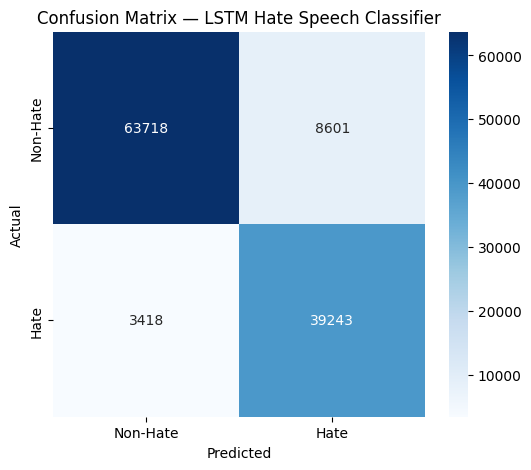

Saved confusion matrix plot.


In [ ]:
# ============================================================
# 1. CONFUSION MATRIX + CLASSIFICATION REPORT
# ============================================================
from sklearn.metrics import confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns

model.eval()
all_preds, all_labels = [], []
with torch.no_grad():
    for texts, labels in test_loader:
        texts, labels = texts.to(device), labels.to(device)
        outputs = model(texts)
        preds = torch.argmax(outputs, dim=1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

cm = confusion_matrix(all_labels, all_preds)
print("Confusion Matrix:")
print(cm)
print(f"\nBreakdown:")
print(f"True Negatives (correctly non-hate):  {cm[0][0]}")
print(f"False Positives (non-hate flagged as hate): {cm[0][1]}")
print(f"False Negatives (hate missed):        {cm[1][0]}")
print(f"True Positives (correctly hate):      {cm[1][1]}")

print("\n" + classification_report(all_labels, all_preds, target_names=['Non-Hate', 'Hate']))

# Visual confusion matrix — useful for your report
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Non-Hate', 'Hate'], yticklabels=['Non-Hate', 'Hate'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix — LSTM Hate Speech Classifier')
plt.savefig('/content/drive/MyDrive/confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved confusion matrix plot.")

In [ ]:
# ============================================================
# 2. SANITY CHECK — HAND-WRITTEN SENTENCES
# ============================================================
def predict_sentence(text, model, vocab, max_len=MAX_LEN):
    model.eval()
    ids = encode(text, vocab, max_len)
    tensor = torch.tensor([ids], dtype=torch.long).to(device)
    with torch.no_grad():
        output = model(tensor)
        probs = torch.softmax(output, dim=1)
        pred = torch.argmax(output, dim=1).item()
        confidence = probs[0][pred].item()
    label = "HATE" if pred == 1 else "NON-HATE"
    return label, confidence

test_sentences = [
    # Should be non-hate
    "I love spending time with my family on weekends",
    "The weather today is really nice for a walk",
    "Great presentation at the meeting, well done team",
    "I disagree with your opinion on this policy",
    "This restaurant serves the best pizza in town",

    # Should be hate
    "go back to your country you don't belong here",
    "these people are ruining everything, they should all leave",
    "I hate all of them, they are disgusting subhuman scum",
    "women shouldn't be allowed to work, they belong at home",
    "all immigrants are criminals and should be deported",

    # Borderline / tricky (edge cases worth checking)
    "I strongly disagree with this group's political views",   # should be non-hate
    "that movie was so bad it should be illegal",               # non-hate, uses "should be illegal"
    "why do people from that country always cause problems",    # subtle bias, ambiguous
]

print(f"{'SENTENCE':<70} {'PREDICTION':<10} {'CONFIDENCE'}")
print("-" * 95)
for sentence in test_sentences:
    label, conf = predict_sentence(sentence, model, vocab)
    print(f"{sentence[:68]:<70} {label:<10} {conf:.3f}")

SENTENCE                                                               PREDICTION CONFIDENCE
-----------------------------------------------------------------------------------------------
I love spending time with my family on weekends                        NON-HATE   0.988
The weather today is really nice for a walk                            NON-HATE   1.000
Great presentation at the meeting, well done team                      NON-HATE   1.000
I disagree with your opinion on this policy                            NON-HATE   1.000
This restaurant serves the best pizza in town                          NON-HATE   1.000
go back to your country you don't belong here                          HATE       0.988
these people are ruining everything, they should all leave             HATE       0.994
I hate all of them, they are disgusting subhuman scum                  HATE       0.999
women shouldn't be allowed to work, they belong at home                HATE       1.000
all immigrants are 

In [ ]:
# ============================================================
# 3. SAVE MODEL + VOCAB (both required for future inference/bot integration)
# ============================================================
import json
import pickle

# Save model weights
torch.save(model.state_dict(), '/content/drive/MyDrive/best_lstm_model.pt')

# Save vocab (needed to tokenize new text identically at inference time)
with open('/content/drive/MyDrive/vocab.json', 'w') as f:
    json.dump(vocab, f)

# Save model config (so you don't have to remember hyperparameters later)
model_config = {
    'vocab_size': VOCAB_SIZE,
    'embed_dim': 128,
    'hidden_dim': 128,
    'num_layers': 2,
    'dropout': 0.3,
    'max_len': MAX_LEN,
}
with open('/content/drive/MyDrive/model_config.json', 'w') as f:
    json.dump(model_config, f)

print("Saved:")
print("  - best_lstm_model.pt (model weights)")
print("  - vocab.json (tokenizer vocabulary)")
print("  - model_config.json (architecture hyperparameters)")
print("\nAll three files needed together for future inference / Discord bot integration.")

Saved:
  - best_lstm_model.pt (model weights)
  - vocab.json (tokenizer vocabulary)
  - model_config.json (architecture hyperparameters)

All three files needed together for future inference / Discord bot integration.
